<a href="https://colab.research.google.com/github/Juanpatula2361/Taller-Redes-Neuronales-II/blob/main/notebooks/01_perceptron_binaria_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 01 — Perceptrón simple y neurona sigmoide con backpropagation (NumPy)

**Curso:** Deep Learning – Conceptos · Especialización en Inteligencia Artificial · Universidad de Cundinamarca
**Semana 2:** funciones de activación y backpropagation aplicadas a clasificación binaria.

En este notebook se retoma el perceptrón de la práctica de Redes Neuronales I y se entrena sobre un dataset
binario **no lineal** (`make_moons`). Se comparan dos versiones:

1. **Perceptrón de Rosenblatt:** activación escalón y regla de actualización $w \leftarrow w + \eta\,(y-\hat{y})\,x$.
2. **Neurona sigmoide entrenada con backpropagation:** activación sigmoide, pérdida de entropía cruzada binaria
   (BCE) y descenso de gradiente. Es el mismo modelo, pero con una activación diferenciable.

Restricción de la práctica: los modelos se implementan **solo con NumPy**. Scikit-learn se usa únicamente para
generar el dataset, dividirlo y estandarizarlo.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Juanpatula2361/Taller-Redes-Neuronales-II/blob/main/notebooks/01_perceptron_binaria_numpy.ipynb)

In [1]:
# ============================================================
# 0. Importaciones y configuración reproducible
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

# Carpeta donde se guardan las figuras (útil para insertarlas en el informe)
FIG_DIR = "figuras"
os.makedirs(FIG_DIR, exist_ok=True)

print("NumPy:", np.__version__)

NumPy: 2.1.3


## 1. Dataset binario: `make_moons`

Se generan 1000 puntos en $\mathbb{R}^2$ organizados en dos "medias lunas" entrelazadas. Clase 0 y clase 1
**no son linealmente separables**, por lo que el dataset permite evidenciar las limitaciones de un modelo lineal.
Se reserva el 20 % para prueba (estratificado) y se estandarizan las características con media y desviación
calculadas **solo** sobre entrenamiento, para evitar fuga de información (*data leakage*).

X_train: (800, 2) | X_test: (200, 2)
Balance de clases (train): [400 400]


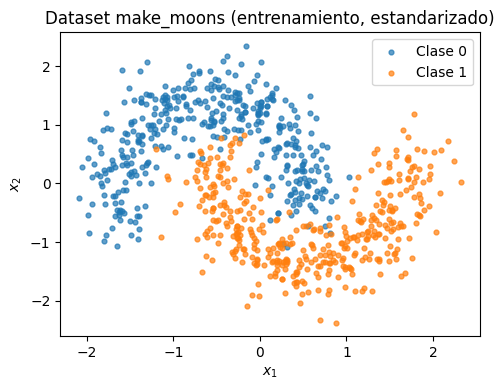

In [2]:
# ============================================================
# 1. Generación, partición y estandarización del dataset
# ============================================================
X, y = make_moons(n_samples=1000, noise=0.20, random_state=SEED)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # ajusta media/desviación con entrenamiento
X_test = scaler.transform(X_test)         # reutiliza esos parámetros en prueba

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Balance de clases (train):", np.bincount(y_train))

plt.figure(figsize=(5, 4))
plt.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], s=12, label="Clase 0", alpha=0.7)
plt.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], s=12, label="Clase 1", alpha=0.7)
plt.title("Dataset make_moons (entrenamiento, estandarizado)")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.legend(); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_dataset_moons.png", dpi=150)
plt.show()

## 2. Perceptrón de Rosenblatt

$$ z = w^\top x + b, \qquad \hat{y} = \begin{cases} 1 & z \ge 0 \\ 0 & z < 0 \end{cases} $$

Regla de actualización (por muestra, solo cuando hay error):

$$ w \leftarrow w + \eta\,(y - \hat{y})\,x, \qquad b \leftarrow b + \eta\,(y - \hat{y}) $$

La función escalón tiene derivada cero en casi todo punto, por eso el perceptrón **no** usa backpropagation:
su regla es heurística y solo converge si los datos son linealmente separables.

In [3]:
# ============================================================
# 2. Perceptrón clásico (activación escalón)
# ============================================================
class Perceptron:
    """Perceptrón de Rosenblatt para clasificación binaria con etiquetas {0, 1}."""

    def __init__(self, n_entradas, lr=0.01, seed=SEED):
        rng = np.random.default_rng(seed)
        self.w = rng.normal(0.0, 0.01, size=n_entradas)   # pesos pequeños aleatorios
        self.b = 0.0
        self.lr = lr

    @staticmethod
    def escalon(z):
        return (z >= 0).astype(int)

    def predict(self, X):
        return self.escalon(X @ self.w + self.b)

    def fit(self, X, y, epochs=50, seed=SEED):
        rng = np.random.default_rng(seed)
        self.historial_errores = []
        for epoch in range(epochs):
            errores = 0
            for i in rng.permutation(len(X)):       # se barajan las muestras en cada época
                y_hat = self.escalon(X[i] @ self.w + self.b)
                delta = y[i] - y_hat                 # 0 si acierta, ±1 si falla
                if delta != 0:
                    self.w += self.lr * delta * X[i]
                    self.b += self.lr * delta
                    errores += 1
            self.historial_errores.append(errores)
        return self


perceptron = Perceptron(n_entradas=2, lr=0.01).fit(X_train, y_train, epochs=50)
acc_perc_train = np.mean(perceptron.predict(X_train) == y_train)
acc_perc_test = np.mean(perceptron.predict(X_test) == y_test)
print(f"Perceptrón -> accuracy train: {acc_perc_train:.4f} | test: {acc_perc_test:.4f}")
print("Pesos:", np.round(perceptron.w, 4), "| bias:", round(perceptron.b, 4))
print("Errores en las últimas 5 épocas:", perceptron.historial_errores[-5:])

Perceptrón -> accuracy train: 0.7475 | test: 0.7950
Pesos: [-0.0046 -0.0106] | bias: -0.0
Errores en las últimas 5 épocas: [171, 172, 154, 160, 151]


## 3. Neurona sigmoide con backpropagation (regresión logística)

**Forward:** $z = Xw + b$, $\;\hat{y} = \sigma(z) = \dfrac{1}{1+e^{-z}}$

**Pérdida (BCE):** $\;\mathcal{L} = -\dfrac{1}{m}\sum_{i=1}^{m}\left[y_i\log\hat{y}_i + (1-y_i)\log(1-\hat{y}_i)\right]$

**Backward (regla de la cadena):**
$\dfrac{\partial \mathcal{L}}{\partial z} = \dfrac{\partial \mathcal{L}}{\partial \hat{y}}\cdot\sigma'(z) = \hat{y} - y$,
por lo tanto $\;\nabla_w\mathcal{L} = \dfrac{1}{m}X^\top(\hat{y}-y)$ y $\;\dfrac{\partial\mathcal{L}}{\partial b} = \dfrac{1}{m}\sum(\hat{y}-y)$.

**Actualización (descenso de gradiente):** $\;w \leftarrow w - \eta\,\nabla_w\mathcal{L}$

In [4]:
# ============================================================
# 3. Neurona sigmoide + BCE + descenso de gradiente
# ============================================================
def sigmoide(z):
    # np.clip evita overflow en exp() para valores extremos de z
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


def bce(y, y_hat, eps=1e-12):
    y_hat = np.clip(y_hat, eps, 1 - eps)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))


class NeuronaSigmoide:
    """Perceptrón con activación sigmoide entrenado por backpropagation (full-batch)."""

    def __init__(self, n_entradas, lr=0.1, seed=SEED):
        rng = np.random.default_rng(seed)
        self.w = rng.normal(0.0, 0.01, size=(n_entradas, 1))
        self.b = 0.0
        self.lr = lr

    def forward(self, X):
        return sigmoide(X @ self.w + self.b)

    def fit(self, X, y, epochs=500):
        y = y.reshape(-1, 1)
        m = len(X)
        self.historial = {"loss": [], "acc": []}
        for epoch in range(epochs):
            y_hat = self.forward(X)                     # forward pass
            self.historial["loss"].append(bce(y, y_hat))
            self.historial["acc"].append(np.mean((y_hat >= 0.5) == y))
            dz = y_hat - y                              # dL/dz (BCE + sigmoide)
            dw = X.T @ dz / m                           # dL/dw
            db = np.mean(dz)                            # dL/db
            self.w -= self.lr * dw                      # actualización
            self.b -= self.lr * db
        return self

    def predict_proba(self, X):
        return self.forward(X).ravel()

    def predict(self, X, umbral=0.5):
        return (self.predict_proba(X) >= umbral).astype(int)


neurona = NeuronaSigmoide(n_entradas=2, lr=0.5).fit(X_train, y_train, epochs=500)
acc_sig_train = np.mean(neurona.predict(X_train) == y_train)
acc_sig_test = np.mean(neurona.predict(X_test) == y_test)
print(f"Neurona sigmoide -> loss final: {neurona.historial['loss'][-1]:.4f}")
print(f"Neurona sigmoide -> accuracy train: {acc_sig_train:.4f} | test: {acc_sig_test:.4f}")

Neurona sigmoide -> loss final: 0.3040
Neurona sigmoide -> accuracy train: 0.8575 | test: 0.9200


## 4. Visualización: curvas de entrenamiento y fronteras de decisión

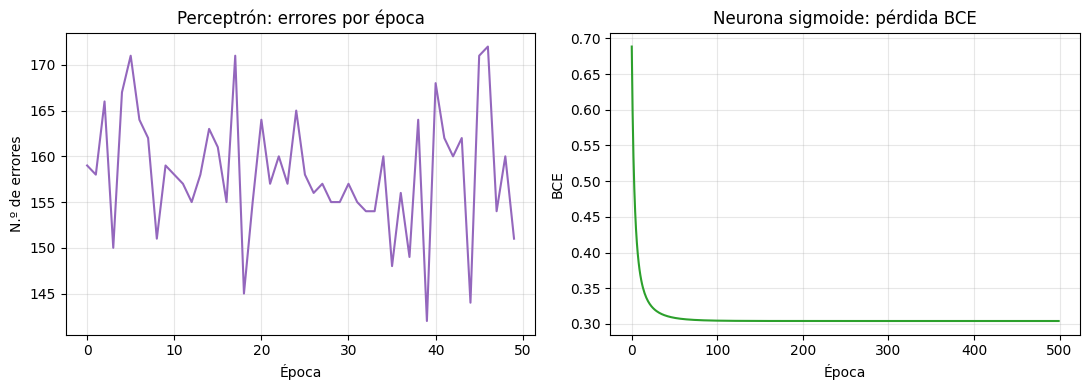

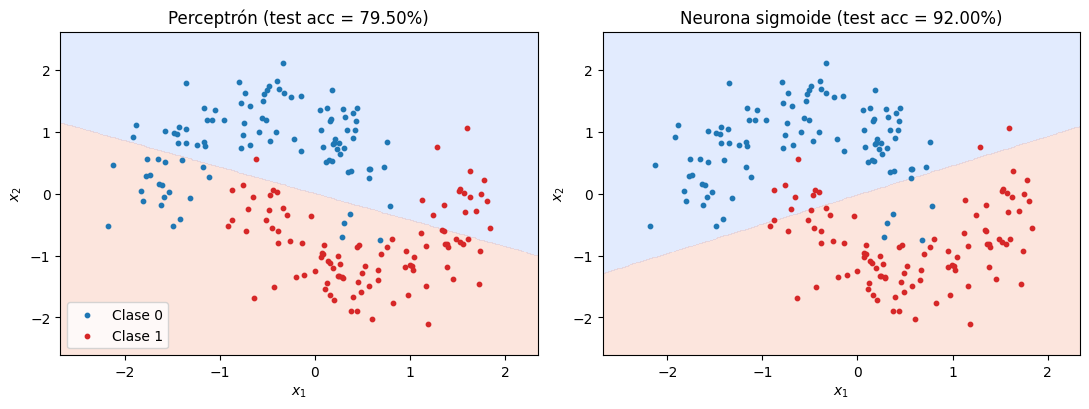

In [5]:
# ============================================================
# 4. Gráficas
# ============================================================
def graficar_frontera(ax, modelo_predict, X, y, titulo):
    """Evalúa el modelo sobre una malla 2D y dibuja la región de decisión."""
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    zz = modelo_predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.1, 0.5, 1.1], alpha=0.25, cmap="coolwarm")
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=10, c="tab:blue", label="Clase 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=10, c="tab:red", label="Clase 1")
    ax.set_title(titulo); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(perceptron.historial_errores, color="tab:purple")
axes[0].set_title("Perceptrón: errores por época"); axes[0].set_xlabel("Época"); axes[0].set_ylabel("N.º de errores")
axes[1].plot(neurona.historial["loss"], color="tab:green")
axes[1].set_title("Neurona sigmoide: pérdida BCE"); axes[1].set_xlabel("Época"); axes[1].set_ylabel("BCE")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_curvas_perceptron.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
graficar_frontera(axes[0], perceptron.predict, X_test, y_test, f"Perceptrón (test acc = {acc_perc_test:.2%})")
graficar_frontera(axes[1], neurona.predict, X_test, y_test, f"Neurona sigmoide (test acc = {acc_sig_test:.2%})")
axes[0].legend(loc="lower left")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_fronteras_perceptron.png", dpi=150); plt.show()

## 5. Análisis

- Ambos modelos producen una **frontera lineal** (una recta en $\mathbb{R}^2$), por lo que su exactitud queda
  limitada: los puntos de las "puntas" de cada luna siempre caen del lado equivocado de la recta.
- El perceptrón **no converge**: como los datos no son linealmente separables, el número de errores por época
  oscila sin llegar a cero y los pesos finales dependen de la última muestra mal clasificada. La neurona
  sigmoide, en cambio, minimiza una pérdida **continua y convexa** (BCE), por lo que su curva de pérdida
  desciende de forma suave y encuentra la mejor recta posible (mayor exactitud que el perceptrón).
- La salida sigmoide se interpreta como $P(y=1\mid x)$, lo que permite ajustar el umbral de decisión.
- Para capturar la forma curva de las lunas se necesita al menos **una capa oculta** con activación no lineal
  (Notebook 02).

In [6]:
!zip -r resultados.zip figuras
from google.colab import files
files.download("resultados.zip")

  adding: figuras/ (stored 0%)
  adding: figuras/01_dataset_moons.png (deflated 3%)
  adding: figuras/01_fronteras_perceptron.png (deflated 12%)
  adding: figuras/01_curvas_perceptron.png (deflated 7%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>